# Phase 2 — Transaction Data: Initial EDA & Problem Acknowledgement

**Dataset:** `MikeGreen2710/transaction_data_26_07_10` — a Hanoi secondary-market brokerage
inventory (~11.3K records, 45 columns). This is *Phase 2*: the move from scraped **asking-price
listings** (Phase 1) toward **transaction/inventory data** with richer features (geocoordinates,
construction year, facade width, road access).

This notebook does two things:
1. **EDA** — understand the structure, prices, geography, and features.
2. **Problem acknowledgement** — surface the data-quality issues *before* any modeling, so the
   next step is chosen with eyes open. See the final section for the consolidated list.

Every cell is runnable top-to-bottom; charts render inline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, RED, GREEN = "#2a78d6", "#c8342f", "#0a9a3c"

# Load from HuggingFace; fall back to the local parquet copy so the notebook is re-runnable offline.
df = None
try:
    from datasets import load_dataset
    df = load_dataset("MikeGreen2710/transaction_data_26_07_10")["train"].to_pandas()
    print("Loaded from HuggingFace.")
except Exception as e:
    print("HuggingFace load failed (", e, ") — trying local copy.")
    for p in ["../data/transaction_data_26_07_10.parquet",
              "data/transaction_data_26_07_10.parquet",
              "Phase 2/data/transaction_data_26_07_10.parquet"]:
        try:
            df = pd.read_parquet(p); print("Loaded local:", p); break
        except FileNotFoundError:
            continue
assert df is not None, "Could not load the dataset from HuggingFace or a local parquet."
print("shape:", df.shape)
df.head(3)

Loaded from HuggingFace.
shape: (11252, 45)


,status,classify,property_id,created_date,last_modified_date,available_for_sale_status,warehouse_import_id,import_price,reference_selling_price,minimum_selling_price,seller_expected_net_income,original_price,selling_furniture,inventory_type,inventory_code,reference_selling_price_gross,commission_rate,UCHI_is_checked,UCHI_info,UCHI_other_info,UCHI_transaction_info,service_contract_status,address_number,ref_property_code,original_latitude,original_longitude,latitude,longitude,land_number_new,map_number_new,total_area,min_waist_width_to_main_road,max_waist_width_to_main_road,main_road_dist,shape_name,facade_width,direction_name,number_of_floors,construction_year,address_number0,main_street_name,ward_name,district_name,short_name,long_name
0,REVOKED,SECONDARY,c37ba6fe-ad67-3afe-1f95-bcb2bfd98b37,09/25/2023,2023-11-12 16:34:46,NOT_AVAILABLE,bffbfcf9-675f-4a20-bf4c-239d02312d31,NaN,3.150000e+09,NaN,NaN,NaN,NO,NORMAL,INV.HC2TWF,3.150000e+09,0.03,NaN,None,None,None,SIGNED,63D,RP00136173202963997,NaN,NaN,21.045557,105.928049,NaN,NaN,30.0,2.0,5.0,50.0,Vuông vức,3.38,NaN,4.0,2022.0,63D,Phúc Lợi,P. Phúc Lợi,Q. Long Biên,Ngõ 197,"Phúc Lợi, P. Phúc Lợi, Q. Long Biên, TP. Hà Nội"
1,REVOKED,SECONDARY,d47b0f5d-2635-6fbc-d7ca-48e754b6eb96,10/19/2023,2024-04-05 01:41:03,NOT_AVAILABLE,10691bc0-b660-49dd-a24e-7a59e3a9f69a,NaN,8.500000e+09,NaN,NaN,NaN,NO,NORMAL,INV.TASZXR,8.500000e+09,0.03,NaN,None,None,None,SIGNED,3,RP00358061504965612,NaN,NaN,20.986914,105.838300,NaN,NaN,63.3,3.0,3.5,5.0,Tương đối vuông vức,3.51,NaN,4.0,2018.0,3,Nguyễn Văn Trỗi,P. Phương Liệt,Q. Thanh Xuân,Ngõ 61,"Nguyễn Văn Trỗi, P. Phương Liệt, Q. Thanh Xuân..."
2,REVOKED,SECONDARY,4fa0ef35-0ab0-3748-be14-f793c00de8b4,11/28/2023,2024-03-14 03:26:23,NOT_AVAILABLE,f5975d0f-7e12-4fbc-84ae-448d211d280c,NaN,3.800000e+09,NaN,NaN,NaN,NO,NORMAL,INV.VEA5NA,3.800000e+09,0.03,NaN,None,None,None,SIGNED,6C,RP00619033653963812,NaN,NaN,21.050474,105.759000,NaN,NaN,30.0,3.0,4.0,200.0,Tương đối vuông vức,3.20,NaN,5.0,2023.0,6C,Đường Phú Diễn,P. Phú Diễn,Q. Bắc Từ Liêm,Ngõ 193/Ngách 220/Hẻm 121/20,"Đường Phú Diễn, P. Phú Diễn, Q. Bắc Từ Liêm, T..."


## 1. Structure & missingness

In [2]:
# Dtype + non-null + missing-% per column, sorted by missingness.
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(dropna=True),
}).sort_values("missing_%", ascending=False)
overview

,dtype,non_null,missing_%,n_unique
original_price,float64,0,100.0,0
UCHI_transaction_info,object,0,100.0,0
UCHI_other_info,object,0,100.0,0
import_price,float64,0,100.0,0
UCHI_info,object,0,100.0,0
minimum_selling_price,float64,0,100.0,0
seller_expected_net_income,float64,0,100.0,0
UCHI_is_checked,float64,0,100.0,0
map_number_new,str,250,97.8,56
land_number_new,str,250,97.8,72


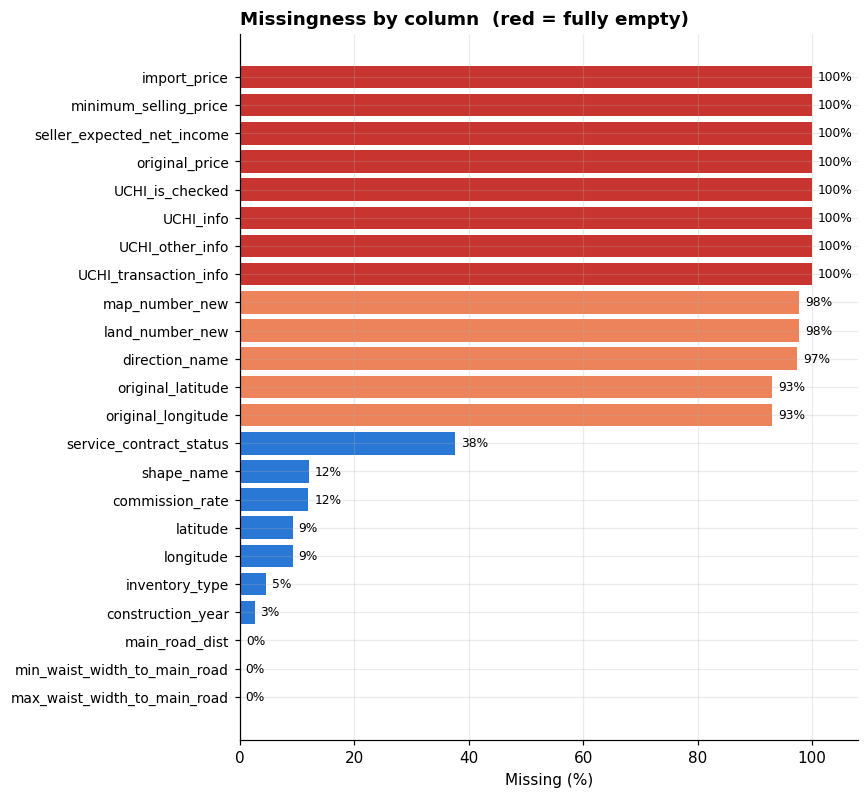

In [3]:
# Missingness of the columns that actually have gaps.
miss = (df.isna().mean() * 100)
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, max(3, len(miss) * 0.32)))
colors = [RED if v >= 99 else "#ec835a" if v >= 40 else BLUE for v in miss.values]
ax.barh(range(len(miss)), miss.values, color=colors)
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index, fontsize=9)
for i, v in enumerate(miss.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel("Missing (%)"); ax.set_xlim(0, 108)
ax.set_title("Missingness by column  (red = fully empty)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 2. The price fields — the central problem

The dataset is named *transaction* data, so the first thing to check is **which price is real**.
There are seven price-related columns — but most are empty.

In [4]:
price_cols = ["import_price", "original_price", "minimum_selling_price", "seller_expected_net_income",
              "reference_selling_price", "reference_selling_price_gross", "commission_rate"]
pd.DataFrame({
    "non_null": df[price_cols].notna().sum(),
    "missing_%": (df[price_cols].isna().mean() * 100).round(1),
}).sort_values("missing_%")

,non_null,missing_%
reference_selling_price,11252,0.0
reference_selling_price_gross,11252,0.0
commission_rate,9900,12.0
import_price,0,100.0
original_price,0,100.0
minimum_selling_price,0,100.0
seller_expected_net_income,0,100.0


In [5]:
# Are reference_selling_price and its 'gross' twin identical?
same = (df["reference_selling_price"].fillna(-1) == df["reference_selling_price_gross"].fillna(-1)).mean() * 100
print(f"reference_selling_price == reference_selling_price_gross : {same:.1f}% of rows")
print("Fully-empty price columns:",
      [c for c in price_cols if df[c].isna().all()])

reference_selling_price == reference_selling_price_gross : 100.0% of rows
Fully-empty price columns: ['import_price', 'original_price', 'minimum_selling_price', 'seller_expected_net_income']


> **Problem 1 — there is no realized/acquisition price.** `import_price`, `original_price`,
> `minimum_selling_price`, and `seller_expected_net_income` are **100% empty**. The only usable
> price is `reference_selling_price` (identical to its `_gross` twin) — a **reference *selling*
> (asking) price**, not a transacted price. So despite the name, this is still asking-price data.

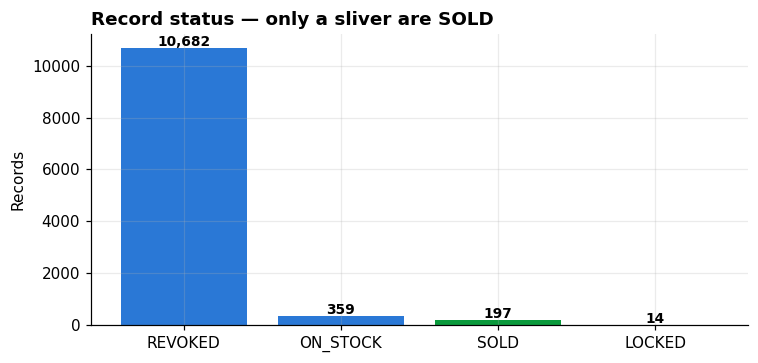

{'REVOKED': 10682, 'ON_STOCK': 359, 'SOLD': 197, 'LOCKED': 14}


In [6]:
# Transaction status — how many are actually SOLD vs revoked inventory?
sc = df["status"].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(sc.index.astype(str), sc.values, color=[GREEN if s == "SOLD" else BLUE for s in sc.index])
for i, v in enumerate(sc.values):
    ax.text(i, v + 80, f"{v:,}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("Records"); ax.set_title("Record status — only a sliver are SOLD", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print(sc.to_dict())

> **Problem 2 — 95% of records are REVOKED, only ~197 are SOLD.** If a "transaction" means a
> completed sale (`status == SOLD`), the usable transaction sample is **tiny (~197 rows)**. The
> bulk is withdrawn/expired inventory carrying a reference asking price.

## 3. Price & price/m² distributions

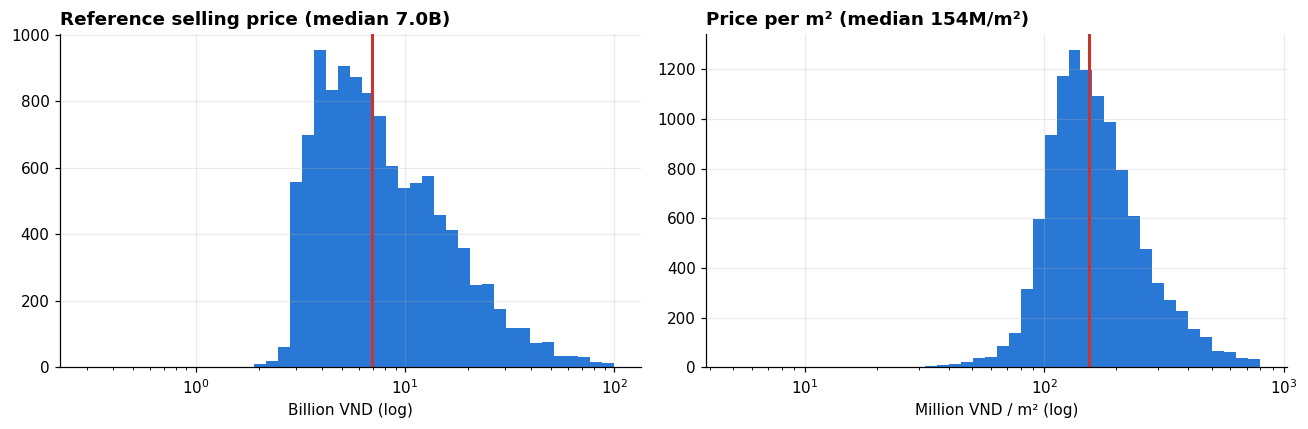

price <= 0: 0 | ppm2 p99: 692.0 M/m²


In [7]:
df["ref_price_bil"] = df["reference_selling_price"] / 1e9
df["ppm2_mil"] = np.where(df["total_area"] > 0, df["reference_selling_price"] / df["total_area"] / 1e6, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p = df["ref_price_bil"]; p = p[(p > 0.1) & (p < 100)]
axes[0].hist(p, bins=np.logspace(np.log10(0.3), np.log10(100), 45), color=BLUE)
axes[0].set_xscale("log"); axes[0].axvline(p.median(), color=RED, lw=2)
axes[0].set_title(f"Reference selling price (median {p.median():.1f}B)", loc="left", fontweight="bold")
axes[0].set_xlabel("Billion VND (log)")

q = df["ppm2_mil"]; q = q[(q > 5) & (q < 800)]
axes[1].hist(q, bins=np.logspace(np.log10(5), np.log10(800), 45), color=BLUE)
axes[1].set_xscale("log"); axes[1].axvline(q.median(), color=RED, lw=2)
axes[1].set_title(f"Price per m² (median {q.median():.0f}M/m²)", loc="left", fontweight="bold")
axes[1].set_xlabel("Million VND / m² (log)")
plt.tight_layout(); plt.show()
print("price <= 0:", (df.reference_selling_price <= 0).sum(),
      "| ppm2 p99:", round(df.ppm2_mil.quantile(.99), 0), "M/m²")

## 4. Geography — a Hanoi secondary market

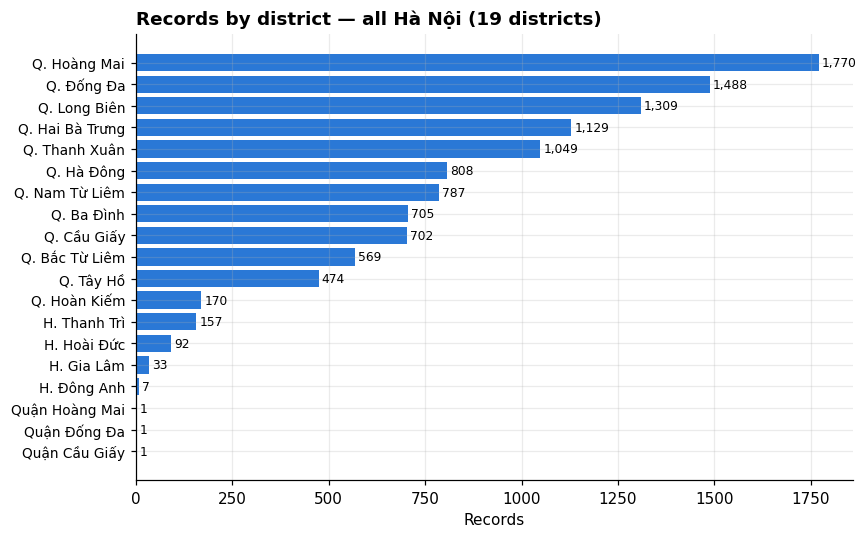

In [8]:
dc = df["district_name"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(dc))[::-1], dc.values, color=BLUE)
ax.set_yticks(range(len(dc))[::-1]); ax.set_yticklabels(dc.index, fontsize=9)
for i, v in zip(range(len(dc))[::-1], dc.values):
    ax.text(v + 8, i, f"{v:,}", va="center", fontsize=8)
ax.set_xlabel("Records"); ax.set_title(f"Records by district — all Hà Nội ({df.district_name.nunique()} districts)",
                                        loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

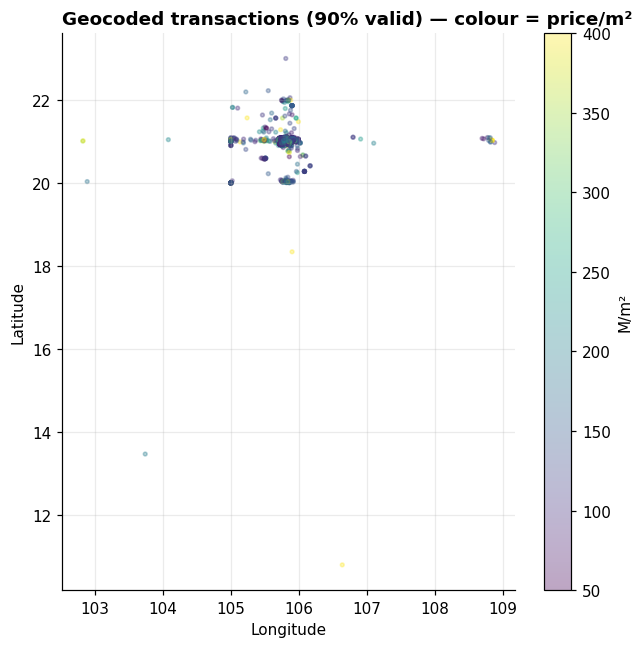

valid coords: 10182 | invalid/missing: 1070 | raw lat range: 0.0 to 90.0


In [9]:
# Coordinate validity (Vietnam bbox) and a scatter of the valid points.
df["geo_valid"] = df["latitude"].between(8, 24) & df["longitude"].between(102, 110)
g = df[df["geo_valid"]]
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(g["longitude"], g["latitude"], s=6, alpha=0.35, c=g["ppm2_mil"].clip(50, 400), cmap="viridis")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"Geocoded transactions ({df.geo_valid.mean()*100:.0f}% valid) — colour = price/m²",
             loc="left", fontweight="bold")
plt.colorbar(sc, label="M/m²"); plt.tight_layout(); plt.show()
print("valid coords:", int(df.geo_valid.sum()), "| invalid/missing:", int((~df.geo_valid).sum()),
      "| raw lat range:", df.latitude.min(), "to", df.latitude.max())

## 5. Structural features — richer than Phase 1

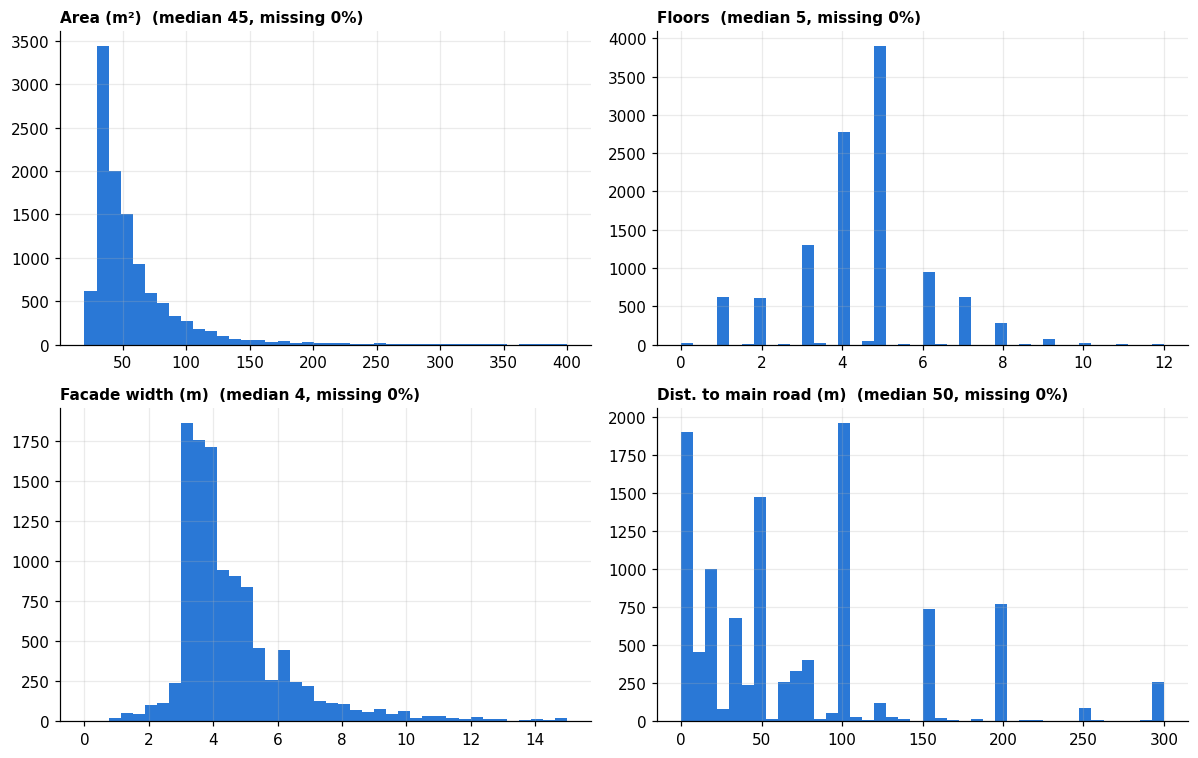

In [10]:
feats = [("total_area", "Area (m²)", 20, 400), ("number_of_floors", "Floors", 0, 12),
         ("facade_width", "Facade width (m)", 0, 15), ("main_road_dist", "Dist. to main road (m)", 0, 300)]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, label, lo, hi) in zip(axes.ravel(), feats):
    v = df[col].dropna(); v = v[(v >= lo) & (v <= hi)]
    ax.hist(v, bins=40, color=BLUE)
    ax.set_title(f"{label}  (median {df[col].median():.0f}, missing {df[col].isna().mean()*100:.0f}%)",
                 loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

construction_year  valid: 10941 | garbage (<1900 or >2026): 16 | missing: 295 | garbage examples: [np.float64(0.0), np.float64(2029.0), np.float64(2032.0), np.float64(2105.0), np.float64(2119.0)]


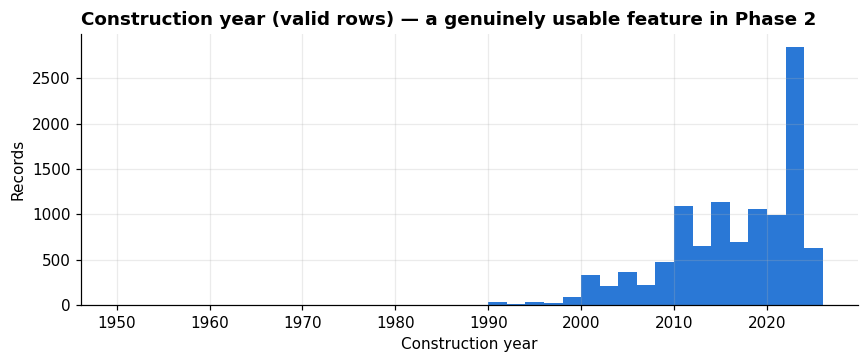

In [11]:
# construction_year — usable here (Phase 1 had it 100% missing), but with some garbage values.
cy = df["construction_year"]
df["cy_valid"] = cy.between(1900, 2026)
print("construction_year  valid:", int(df.cy_valid.sum()),
      "| garbage (<1900 or >2026):", int((~df.cy_valid & cy.notna()).sum()),
      "| missing:", int(cy.isna().sum()),
      "| garbage examples:", sorted(cy[~df.cy_valid & cy.notna()].unique())[:6])
v = cy[df.cy_valid]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(v, bins=range(1950, 2028, 2), color=BLUE)
ax.set_xlabel("Construction year"); ax.set_ylabel("Records")
ax.set_title("Construction year (valid rows) — a genuinely usable feature in Phase 2", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. Duplicates & dates

In [12]:
dup = df.duplicated("property_id").sum()
print(f"property_id: {df.property_id.nunique():,} unique of {len(df):,}  ->  {dup:,} duplicate rows")
# a property_id that appears multiple times (same property re-listed / re-priced?)
ex = df["property_id"].value_counts()
ex = ex[ex > 1].index[0]
cols = ["property_id", "status", "reference_selling_price", "created_date", "last_modified_date"]
display(df[df.property_id == ex][cols])

df["created"] = pd.to_datetime(df["created_date"], format="%m/%d/%Y", errors="coerce")
print("\ncreated_date range:", df.created.min().date(), "->", df.created.max().date(),
      "| unparseable:", int(df.created.isna().sum()))
print("last_modified_date range:", df.last_modified_date.min(), "->", df.last_modified_date.max())

property_id: 10,506 unique of 11,252  ->  746 duplicate rows


,property_id,status,reference_selling_price,created_date,last_modified_date
457,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,10/14/2023,2023-10-14 02:21:54
627,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05
1711,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,10/14/2023,2023-10-14 02:21:54
3524,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05
3601,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05
4371,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,10/14/2023,2023-10-14 02:21:54
5039,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,10/14/2023,2023-10-14 02:21:54
5360,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05
5437,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05
6417,d18f2803-a2d1-d8e4-ef37-b23ee82a72a4,REVOKED,4.450000e+09,09/24/2023,2023-10-13 17:01:05



created_date range: 2023-09-15 -> 2024-05-06 | unparseable: 0
last_modified_date range: 2023-09-15 12:01:21 -> 2026-07-06 04:53:18


## 7. Problem acknowledgements — the key takeaway before Phase 2 modeling

**Blocking / scope issues**
1. **No realized transaction price.** `import_price`, `original_price`, `minimum_selling_price`,
   `seller_expected_net_income` are **100% empty**. Only `reference_selling_price` (an *asking*
   price) survives — so this is not yet the transaction-price signal we hoped for.
2. **Only ~197 SOLD records.** 95% are `REVOKED`. A true "sold-price" model would have a *tiny*
   sample; using all rows means modeling **asking** prices again (like Phase 1).
3. **Hà Nội only, secondary market, ~11K rows.** Much smaller and geographically narrower than
   Phase 1 (704K, multi-city). Median area is small (~45 m², inner-city) and price/m² is high
   (~155 M/m²) — a different market segment.

**Data-quality issues (fixable)**
4. **8 fully-empty columns** (the price fields above + `UCHI_*`) — drop them.
5. **Invalid coordinates:** ~9–10% of rows have missing or out-of-range lat/long (0 or 90);
   geocode-based features need those rows filtered or re-geocoded.
6. **Garbage construction years** (0, 2119, …) — a handful; clip to 1900–2026.
7. **~746 duplicate `property_id`s** — same property appearing multiple times (re-listings /
   price changes). Decide whether to keep the latest, the SOLD record, or all.
8. **Mixed date formats** — `created_date` is a `MM/DD/YYYY` string, `last_modified_date` is a
   datetime. `created_date` spans ~8 months (2023-09 → 2024-05).
9. **Very high missingness** on `direction_name` (97%), `land/map_number_new` (98%),
   `service_contract_status` (38%), `shape_name` (12%) — limited usefulness as features.

**The upside (why Phase 2 is still worth it)**
- **`construction_year` is 97% usable** (was 100% missing in Phase 1).
- **Real geocoordinates** for ~90% of rows → street/neighbourhood-level location, the exact lever
  Phase 1 lacked.
- **Richer structure:** `facade_width`, `main_road_dist`, `shape_name`, waist widths.

**Open decisions for the next step (yours to make):**
- Target: model **`reference_selling_price`** on all rows (asking, big sample) **or** restrict to
  **SOLD** (transaction, ~197 rows)?
- Scope: keep as a standalone Hà Nội model, or align/merge with Phase 1?
- Which of the rich new features (geo, construction year, facade) to bring in first?